# 02. Оцінка: чи піднімає CNN decode rate

Порівнюємо ланцюжок спроб, як на лінії:
- **raw**: декодер читає кадр як є (baseline);
- **camera**: якщо raw дав No Read, ще спроба після класичної обробки (CLAHE і різкість).
  Це імітація вбудованих фільтрів промислової камери, без нейромережі;
- **camera→cnn**: якщо й camera дала No Read, кадр проходить через U-Net і декодер пробує ще раз.

Дві моделі: **syn** (лише синтетика) і **mix** (синтетика + реальні фото, модель для лінії).

Метрики: **decode rate** (частка правильно прочитаних), **хибні декоди** (прочитав, але не те),
**мс на кадр** (усі спроби ланцюжка). Декодери: zxing-cpp (усі формати),
OpenCV (лише EAN-13 і EAN-8), WeChat (лише QR).

In [10]:
import sys
from pathlib import Path

# ноутбук лежить у notebooks/, корінь проєкту на рівень вище
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [11]:
import itertools
import cv2
from tqdm.auto import tqdm

from src.data import generate_synthetic, load_real_split
from src.decoders import DECODERS, check, decoders_for
from src.degradations import DEGRADATIONS
from src.model import load_model, restore

models = {
    "syn": load_model(MODELS / "unet_synthetic.pt"),
    "mix": load_model(MODELS / "unet_mix.pt"),
}

In [12]:
def classic(image):
    """Імітація вбудованої обробки промислової камери (без нейромережі).

    Легке розмиття проти шуму -> CLAHE (локальний контраст) -> підвищення різкості.
    Параметри підібрані на train-фото.
    """
    smooth = cv2.GaussianBlur(image, (3, 3), 0)
    contrast = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(smooth)
    blur = cv2.GaussianBlur(contrast, (0, 0), 2)
    return cv2.addWeighted(contrast, 1.5, blur, -0.5, 0)


def evaluate(samples, degradations, levels):
    """Таблиця: один рядок = (кадр, декодер, метод) -> outcome, ms.

    Кожна наступна спроба запускається, лише якщо попередня дала No Read.
    Якщо спроба щось прочитала, беремо це (на лінії ми не знаємо, чи воно правильне).
    """
    rows = []
    jobs = [(sample, "clean", 0) for sample in samples]
    jobs += list(itertools.product(samples, degradations, levels))
    for sample, name, level in tqdm(jobs):
        if name == "clean":
            image = sample["image"]
        else:
            image = DEGRADATIONS[name](sample["image"], level, seed=level)

        start = time.perf_counter()
        enhanced = classic(image)
        classic_ms = (time.perf_counter() - start) * 1000

        restored, cnn_ms = {}, {}
        for model_name, model in models.items():
            start = time.perf_counter()
            restored[model_name] = restore(model, image)
            cnn_ms[model_name] = (time.perf_counter() - start) * 1000

        for decoder in decoders_for(sample["format"]):
            info = {"sample": sample["id"], "source": sample.get("source", "synthetic"),
                    "format": sample["format"], "degradation": name, "level": level,
                    "decoder": decoder}

            start = time.perf_counter()
            raw_outcome = check(DECODERS[decoder](image), sample["text"])
            raw_ms = (time.perf_counter() - start) * 1000
            rows.append({**info, "method": "raw", "outcome": raw_outcome, "ms": raw_ms})

            # camera: при No Read ще спроба після класичної обробки
            camera_outcome, camera_ms = raw_outcome, raw_ms
            if raw_outcome == "none":
                start = time.perf_counter()
                camera_outcome = check(DECODERS[decoder](enhanced), sample["text"])
                camera_ms = raw_ms + classic_ms + (time.perf_counter() - start) * 1000
            rows.append({**info, "method": "camera", "outcome": camera_outcome, "ms": camera_ms})

            # camera->cnn: якщо й камера не прочитала, пробуємо кадр після CNN
            for model_name in models:
                outcome, ms = camera_outcome, camera_ms
                if camera_outcome == "none":
                    start = time.perf_counter()
                    outcome = check(DECODERS[decoder](restored[model_name]), sample["text"])
                    ms = camera_ms + cnn_ms[model_name] + (time.perf_counter() - start) * 1000
                rows.append({**info, "method": "camera→cnn_" + model_name, "outcome": outcome, "ms": ms})
    return pd.DataFrame(rows)


def summarize(table, by):
    """decode rate, частка хибних декодів і медіана мс для кожної групи."""
    table = table.assign(correct=table["outcome"] == "correct", wrong=table["outcome"] == "wrong")
    return table.groupby(by).agg(decode_rate=("correct", "mean"), wrong_rate=("wrong", "mean"),
                                 ms=("ms", "median"), frames=("correct", "size")).round(3)


def rate_table(table):
    """decode rate: рядки = пошкодження, колонки = методи, плюс рядок "усі"."""
    rates = summarize(table, ["degradation", "method"])["decode_rate"].unstack()[METHODS]
    rates.loc["усі"] = summarize(table, ["method"])["decode_rate"][METHODS]
    return rates


def recovered_no_read(table, method):
    """Яку частку кадрів з No Read на raw метод повернув правильно."""
    key = ["sample", "degradation", "level", "decoder"]
    raw = table[table["method"] == "raw"].set_index(key)["outcome"]
    other = table[table["method"] == method].set_index(key)["outcome"]
    no_read = raw == "none"
    return round((other[no_read] == "correct").mean(), 3)


METHODS = ["raw", "camera", "camera→cnn_syn", "camera→cnn_mix"]

## 1. Реальні фото: test-частини трьох наборів

- Arte-Lab: EAN-13, CC BY 3.0 (Zamberletti, Gallo, Albertini, ACPR 2013), `scripts/download_artelab.py`;
- ParcelBar, InventBar: CC BY-SA 4.0 (Kamnardsiri et al., Sensors 2022), `scripts/download_kaggle.py`.

Вміст кодів у наборах не вказано, тому правильна відповідь = те, що zxing-cpp прочитав на
оригіналі (для EAN-13 і EAN-8 разом з OpenCV). Тест = ті коди, яких модель `mix` не бачила
(той самий поділ, що в 01). Модель `syn` не бачила жодного реального фото.
Рівні пошкоджень 1, 3, 5 (щоб прогін був швидшим).

In [13]:
real_train, real_test = load_real_split()
real = evaluate(real_test, list(DEGRADATIONS), [1, 3, 5])
real.to_csv(RESULTS / "real.csv", index=False)
summarize(real, ["decoder", "method"])

artelab: 247 фото з відповіддю -> train 166, test 81
parcelbar: 183 фото з відповіддю -> train 128, test 55
inventbar: 416 фото з відповіддю -> train 291, test 125


100%|██████████| 5742/5742 [12:16<00:00,  7.80it/s]  


decode_rate  wrong_rate       ms  frames
decoder method                                                  
opencv  camera                0.637       0.007    3.523    2750
        camera→cnn_mix        0.697       0.013    3.523    2750
        camera→cnn_syn        0.709       0.021    3.523    2750
        raw                   0.570       0.005    2.601    2750
wechat  camera                0.386       0.000  186.227      88
        camera→cnn_mix        0.443       0.000  205.342      88
        camera→cnn_syn        0.455       0.000  195.103      88
        raw                   0.375       0.000  103.544      88
zxing   camera                0.610       0.003    8.932    5742
        camera→cnn_mix        0.690       0.003   18.871    5742
        camera→cnn_syn        0.690       0.004   18.871    5742
        raw                   0.470       0.002    6.008    5742

### Decode rate за типом пошкодження (zxing-cpp)

In [14]:
real_zxing = real[real["decoder"] == "zxing"]
rate_table(real_zxing)

method,raw,camera,camera→cnn_syn,camera→cnn_mix
degradation,,,,
clean,1.000,1.000,1.000,1.000
dark,0.433,0.605,0.761,0.679
defocus,0.223,0.266,0.327,0.331
glare,0.536,0.656,0.713,0.733
jpeg,0.659,0.847,0.879,0.888
motion_blur,0.304,0.336,0.336,0.342
noise,0.342,0.610,0.777,0.801
uneven,0.614,0.819,0.932,0.955
усі,0.470,0.610,0.690,0.690


### За набором і частка повернутих No Read (zxing-cpp)

In [15]:
by_source = summarize(real_zxing, ["source", "method"])["decode_rate"].unstack()[METHODS]
by_source.loc["усі"] = summarize(real_zxing, ["method"])["decode_rate"][METHODS]
print("Повернуто No Read: camera", recovered_no_read(real_zxing, "camera"),
      "| camera→cnn_syn", recovered_no_read(real_zxing, "camera→cnn_syn"),
      "| camera→cnn_mix", recovered_no_read(real_zxing, "camera→cnn_mix"))
by_source

Повернуто No Read: camera 0.265 | camera→cnn_syn 0.416 | camera→cnn_mix 0.417


method,raw,camera,camera→cnn_syn,camera→cnn_mix
source,,,,
artelab,0.467,0.646,0.734,0.721
inventbar,0.455,0.595,0.669,0.684
parcelbar,0.507,0.591,0.672,0.661
усі,0.470,0.610,0.690,0.690


## 2. Синтетика: незнайомі коди (test, seed 2)

30 кодів кожного формату × (чистий + 7 пошкоджень × 5 рівнів).

In [16]:
synthetic_test = generate_synthetic(n_per_format=30, seed=2)
synthetic = evaluate(synthetic_test, list(DEGRADATIONS), [1, 2, 3, 4, 5])
synthetic.to_csv(RESULTS / "synthetic.csv", index=False)
synthetic_zxing = synthetic[synthetic["decoder"] == "zxing"]
rate_table(synthetic_zxing)

100%|██████████| 3240/3240 [01:20<00:00, 40.10it/s]


method,raw,camera,camera→cnn_syn,camera→cnn_mix
degradation,,,,
clean,0.978,0.978,0.978,0.978
dark,0.613,0.767,0.907,0.847
defocus,0.271,0.309,0.618,0.460
glare,0.711,0.753,0.809,0.811
jpeg,0.887,0.911,0.911,0.911
motion_blur,0.200,0.278,0.351,0.300
noise,0.660,0.831,0.911,0.911
uneven,0.478,0.524,0.960,0.960
усі,0.558,0.635,0.786,0.749


## 3. Графіки

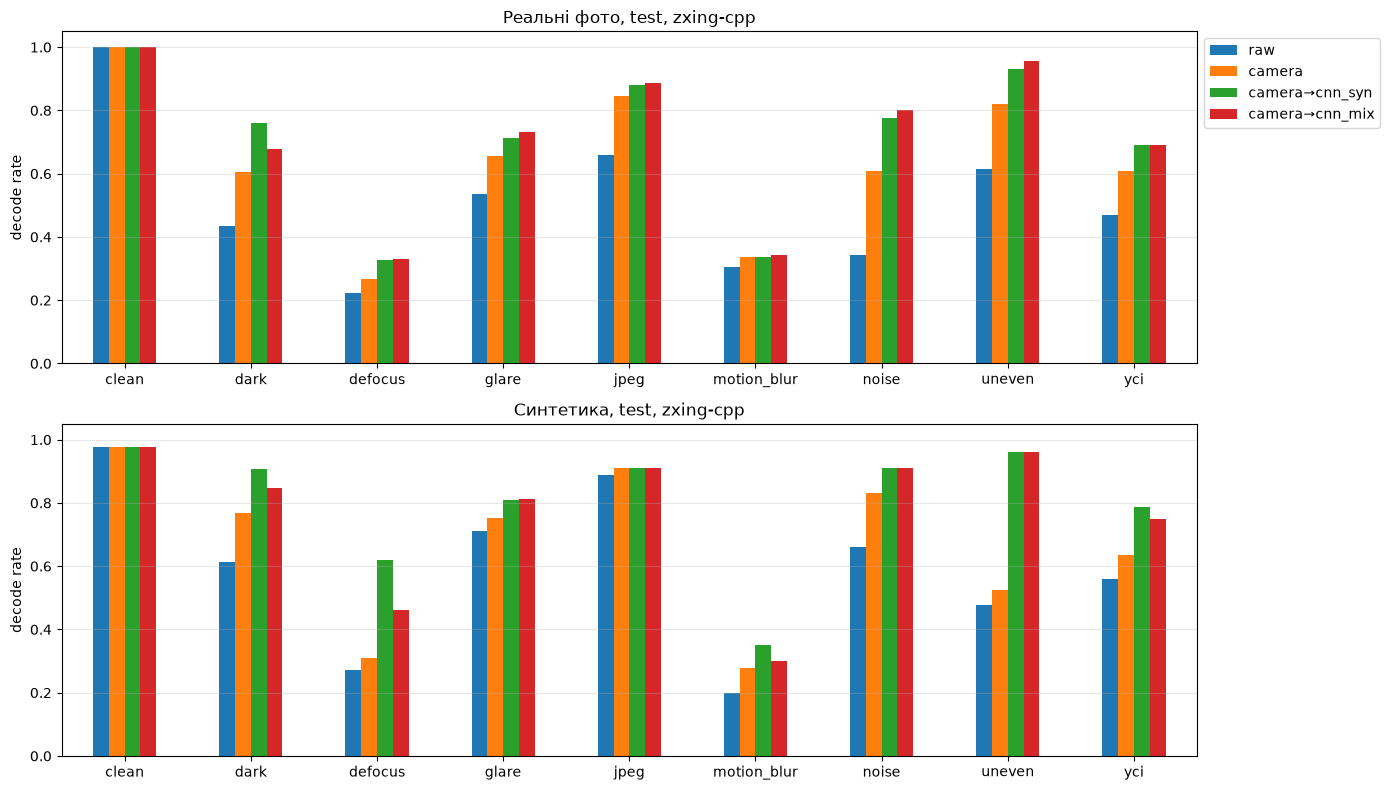

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=True)
for ax, (title, part) in zip(axes, [("Реальні фото, test", real_zxing), ("Синтетика, test", synthetic_zxing)]):
    rate_table(part)[METHODS].plot.bar(ax=ax, rot=0, legend=False)
    ax.set_title(title + ", zxing-cpp")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.set_ylabel("decode rate")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig(RESULTS / "fig_overall.png", dpi=100)
plt.show()

### Приклади на test-фото: вхід, камера (CLAHE) і дві моделі

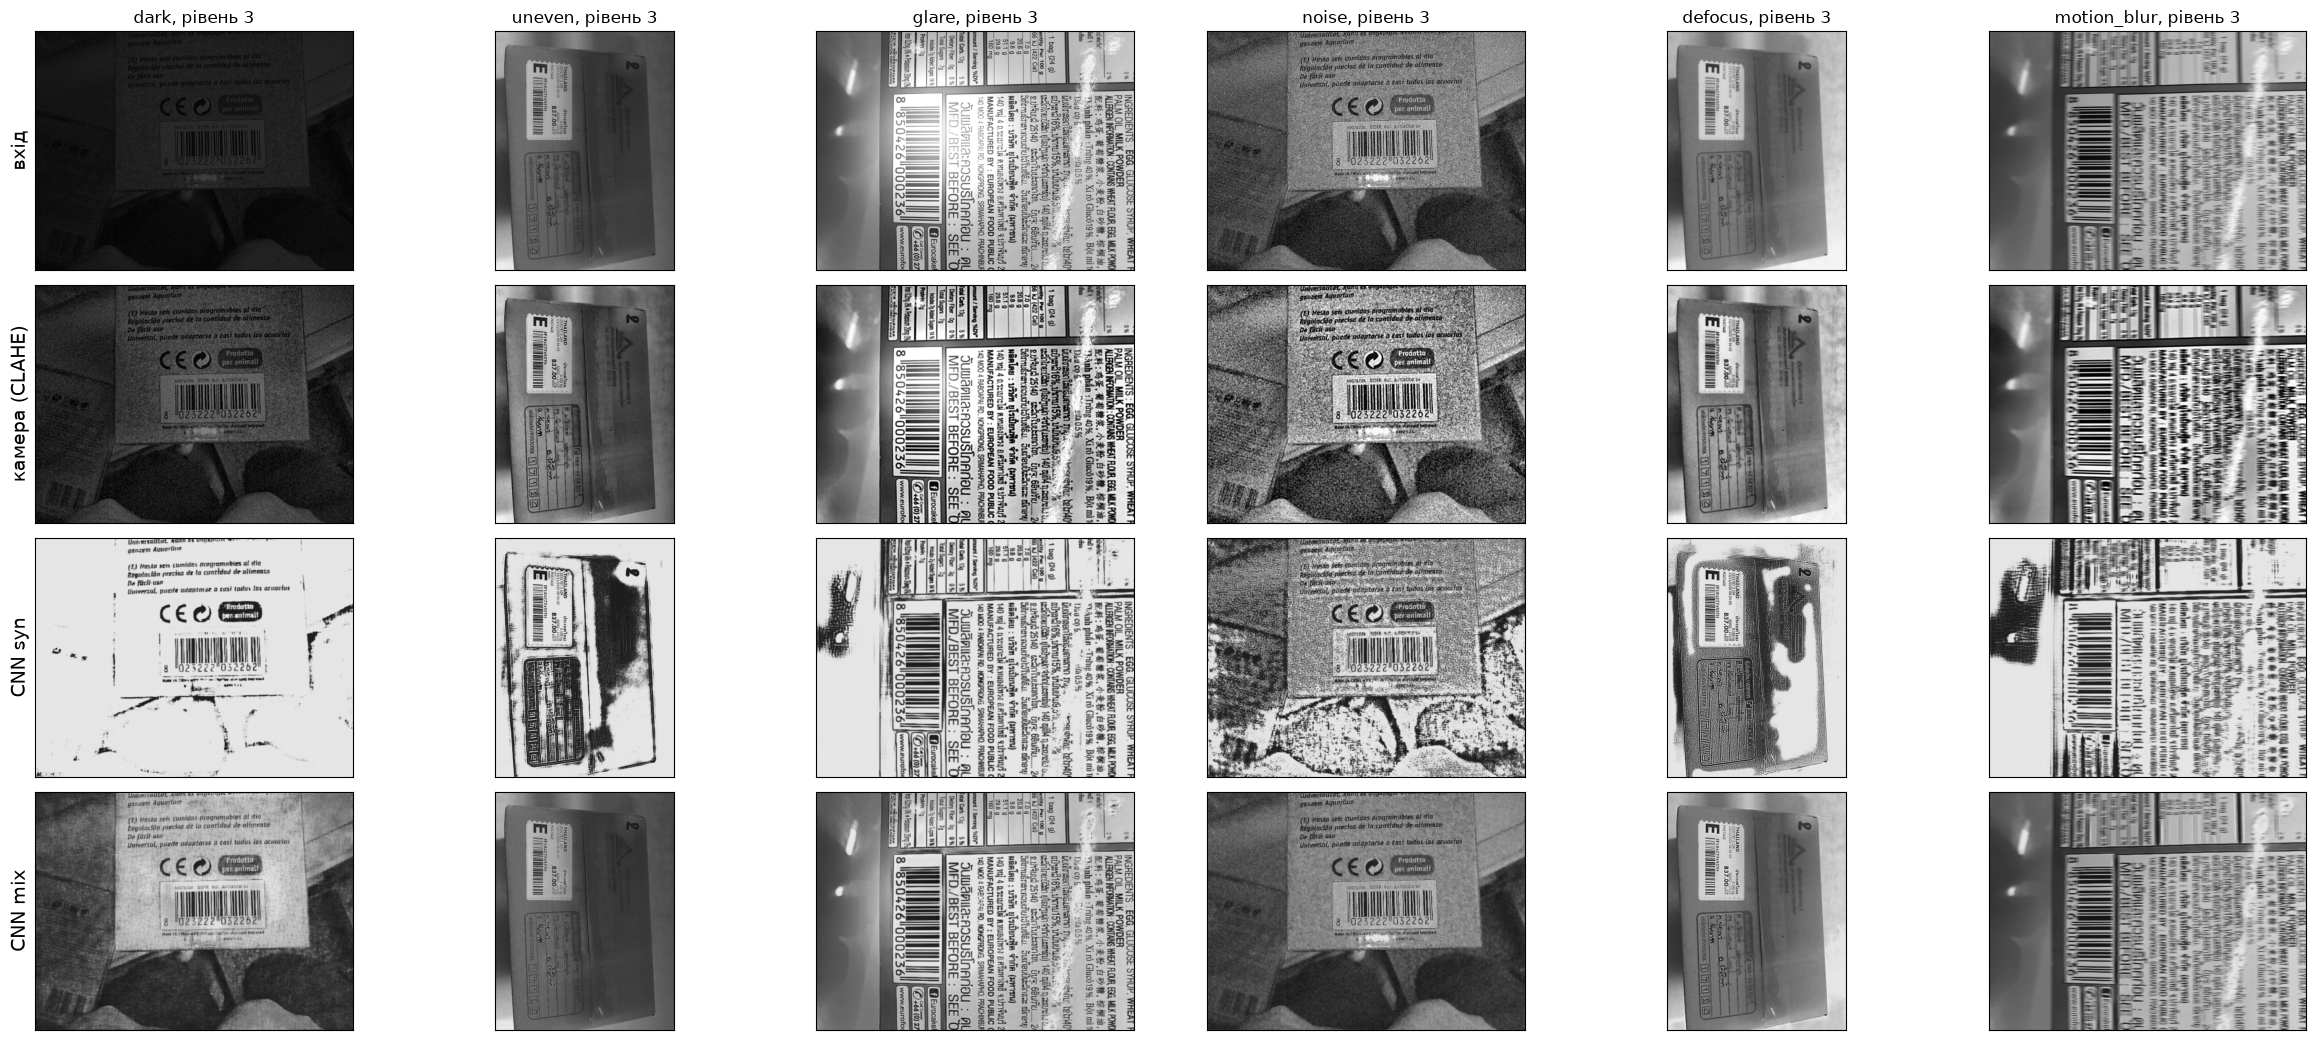

In [18]:
examples = ["dark", "uneven", "glare", "noise", "defocus", "motion_blur"]
# по одному фото з кожного набору по черзі
pictures = [real_test[0], [s for s in real_test if s["source"] == "parcelbar"][0],
            [s for s in real_test if s["source"] == "inventbar"][0]] * 2
fig, axes = plt.subplots(4, len(examples), figsize=(24, 10.5))
for i, name in enumerate(examples):
    damaged = DEGRADATIONS[name](pictures[i]["image"], 3, seed=3)
    images = [damaged, classic(damaged)] + [restore(models[model_name], damaged) for model_name in models]
    for row, image in enumerate(images):
        axes[row, i].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[0, i].set_title(name + ", рівень 3")
for row, label in enumerate(["вхід", "камера (CLAHE)", "CNN syn", "CNN mix"]):
    axes[row, 0].set_ylabel(label, fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS / "examples.png", dpi=80)
plt.show()

## 4. Чому не всі кадри читаються

Загальний decode rate усереднює всі пошкодження і рівні, зокрема ті, де код уже не відновити:
- **Розмиття** (defocus, motion_blur) з рівня 3: смуги шириною 2–3 пікселі зливаються в сірий колір.
  Це ~58% усіх невдач.
- **Рівень 5 темряви й відблиску:** смуги тонуть у чорному або засвічені до білого.
- **Освітлення, шум і JPEG на рівнях 1–3:** після CNN не читається лише 1–11% кадрів.

Такі кадри виправляє обладнання (роздільність, коротка витримка, світло), а не обробка зображення.

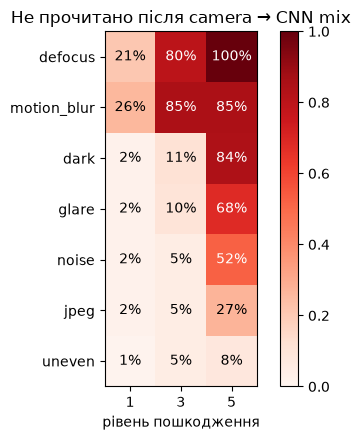

level,1,3,5,частка всіх невдач
degradation,,,,
defocus,0.21,0.80,1.00,0.29
motion_blur,0.26,0.85,0.85,0.29
dark,0.02,0.11,0.84,0.14
glare,0.02,0.10,0.68,0.12
noise,0.02,0.05,0.52,0.09
jpeg,0.02,0.05,0.27,0.05
uneven,0.01,0.05,0.08,0.02


In [19]:
# частка НЕ прочитаних кадрів після camera→cnn_mix (реальні фото, zxing)
chain = real_zxing[(real_zxing["method"] == "camera→cnn_mix") & (real_zxing["degradation"] != "clean")]
chain = chain.assign(failed=chain["outcome"] != "correct")
failures = chain.pivot_table(index="degradation", columns="level", values="failed")
failures["частка всіх невдач"] = chain[chain["failed"]].groupby("degradation").size() / chain["failed"].sum()
failures = failures.fillna(0)
failures = failures.sort_values("частка всіх невдач", ascending=False).round(2)

fig, ax = plt.subplots(figsize=(5, 4.5))
picture = ax.imshow(failures[[1, 3, 5]], cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(3), ["1", "3", "5"])
ax.set_xlabel("рівень пошкодження")
ax.set_yticks(range(len(failures)), failures.index)
for row in range(len(failures)):
    for col, level in enumerate([1, 3, 5]):
        value = failures.iloc[row][level]
        ax.text(col, row, f"{value:.0%}", ha="center", va="center",
                color="white" if value > 0.5 else "black")
ax.set_title("Не прочитано після camera → CNN mix")
plt.colorbar(picture)
plt.tight_layout()
plt.savefig(RESULTS / "fig_failures.png", dpi=100)
plt.show()
failures

## Висновки

1. Реальні test-фото (261, zxing): raw 47.0% → камера (CLAHE) 61.0% → камера + CNN mix 69.0%. Класична обробка дає +14 п.п., CNN додає ще +8 п.п. і повертає 21% кадрів, які не прочитала камера.
2. syn і mix у ланцюжку однакові за decode rate, але mix удвічі рідше дає хибні декоди OpenCV (1.3% проти 2.1%): syn домальовує текстури фону. Модель для лінії: mix.
3. CNN найкраще виправляє освітлення і шум: нерівне світло 82→96%, шум 61→80%. На рівнях 1–3 освітлення, шуму і JPEG не читається лише 4% кадрів.
4. Розмиття не виправляє жоден метод: це 58% усіх невдач. Смуги шириною 2–3 пікселі зливаються, інформації немає. Це вирішує обладнання (роздільність, витримка, світло).
5. CNN запускається лише при No Read камери. Весь ланцюжок для такого кадру займає ~35 мс на Mac Mini M4 (MPS).
6. Обмеження: "камера" тут лише імітація. Справжній зчитувач має сильніший декодер і кілька кадрів на коробку, тому приріст на лінії може бути меншим.